# Evaluation of trained word2vec embeddings
This evaluation is intended as a light check of whether the trained embeddings
capture measurable structure beyond random initialization.

In [1]:
import sys
from pathlib import Path

project_root = Path().resolve().parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

import json
import numpy as np
from scipy.stats import spearmanr
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

from src.model import SkipGramNegativeSampling

## Helpers

In [2]:
def cosine_similarity(a, b):
    dot = np.dot(a, b)
    norm = np.linalg.norm(a) * np.linalg.norm(b)
    if norm == 0:
        return 0.0
    return dot / norm


def load_wordsim353(path="../data/eval/wordsim353crowd.csv"):
    pairs = []
    with open(path, "r") as f:
        next(f)  
        for line in f:
            parts = line.strip().split(",")
            if len(parts) < 3:
                continue
            w1, w2 = parts[0].lower(), parts[1].lower()
            try:
                score = float(parts[2])
            except ValueError:
                continue
            pairs.append((w1, w2, score))
    return pairs

## Load saved embeddings

In [3]:

embeddings = np.load("../artifacts/embeddings.npy")
with open("../artifacts/vocab.json", "r") as f:
    vocab = json.load(f)

word2idx = {w: i for i, w in enumerate(vocab)}
vocab_size, embedding_dim = embeddings.shape

## WordSim-353 evaluation
Spearman correlation between human similarity judgments and cosine similarity of our embeddings.
We compare against a random baseline (same architecture, no training) to verify that training actually learned something.

In [4]:
def evaluate_wordsim(emb, word2idx, pairs):
    human_scores = []
    model_scores = []
    skipped = 0

    for w1, w2, human in pairs:
        if w1 not in word2idx or w2 not in word2idx:
            skipped += 1
            continue
        sim = cosine_similarity(emb[word2idx[w1]], emb[word2idx[w2]])
        human_scores.append(human)
        model_scores.append(sim)

    total = len(pairs)
    covered = total - skipped
    rho, pvalue = spearmanr(human_scores, model_scores)

    return rho, pvalue, covered, total


wordsim_pairs = load_wordsim353()

# Trained embeddings
rho_trained, p_trained, covered, total = evaluate_wordsim(embeddings, word2idx, wordsim_pairs)

# Random baseline - same architecture, no training
random_model = SkipGramNegativeSampling(vocab_size=vocab_size, embedding_dim=embedding_dim, seed=0)
random_emb = random_model.get_input_embeddings()
rho_random, p_random, _, _ = evaluate_wordsim(random_emb, word2idx, wordsim_pairs)

print(f"WordSim-353 coverage: {covered}/{total} pairs ({100 * covered / total:.1f}%)")
print(f"Random baseline:  ρ = {rho_random:.4f}  (p = {p_random:.4f})")
print(f"Trained:          ρ = {rho_trained:.4f}  (p = {p_trained:.4f})")

WordSim-353 coverage: 299/353 pairs (84.7%)
Random baseline:  ρ = 0.0361  (p = 0.5336)
Trained:          ρ = 0.4396  (p = 0.0000)


On WordSim-353, the trained embeddings reach **ρ = 0.4396** on the covered pairs,
compared with **ρ = 0.0361** for the random baseline. The p-value is effectively zero, while the random baseline p-value is
**0.5336**. Taken together, these results show that the trained embeddings have a
higher rank correlation with human similarity judgments than random vectors on this
benchmark subset.

Coverage is **299/353 pairs (84.7%)**, so the reported correlation is computed only
on the portion of the benchmark present in the model vocabulary. This means the result
should be interpreted as performance on the covered subset, not on the full dataset.
For that reason, I do not treat this number as directly comparable to results obtained
with different vocabularies, preprocessing pipelines, or corpora.

## PCA 
2D projection of selected words. We pick words from a few semantic categories
(sports, places, people, time, science, actions) to see if the model groups them sensibly.

Total explained variance: 22.096%


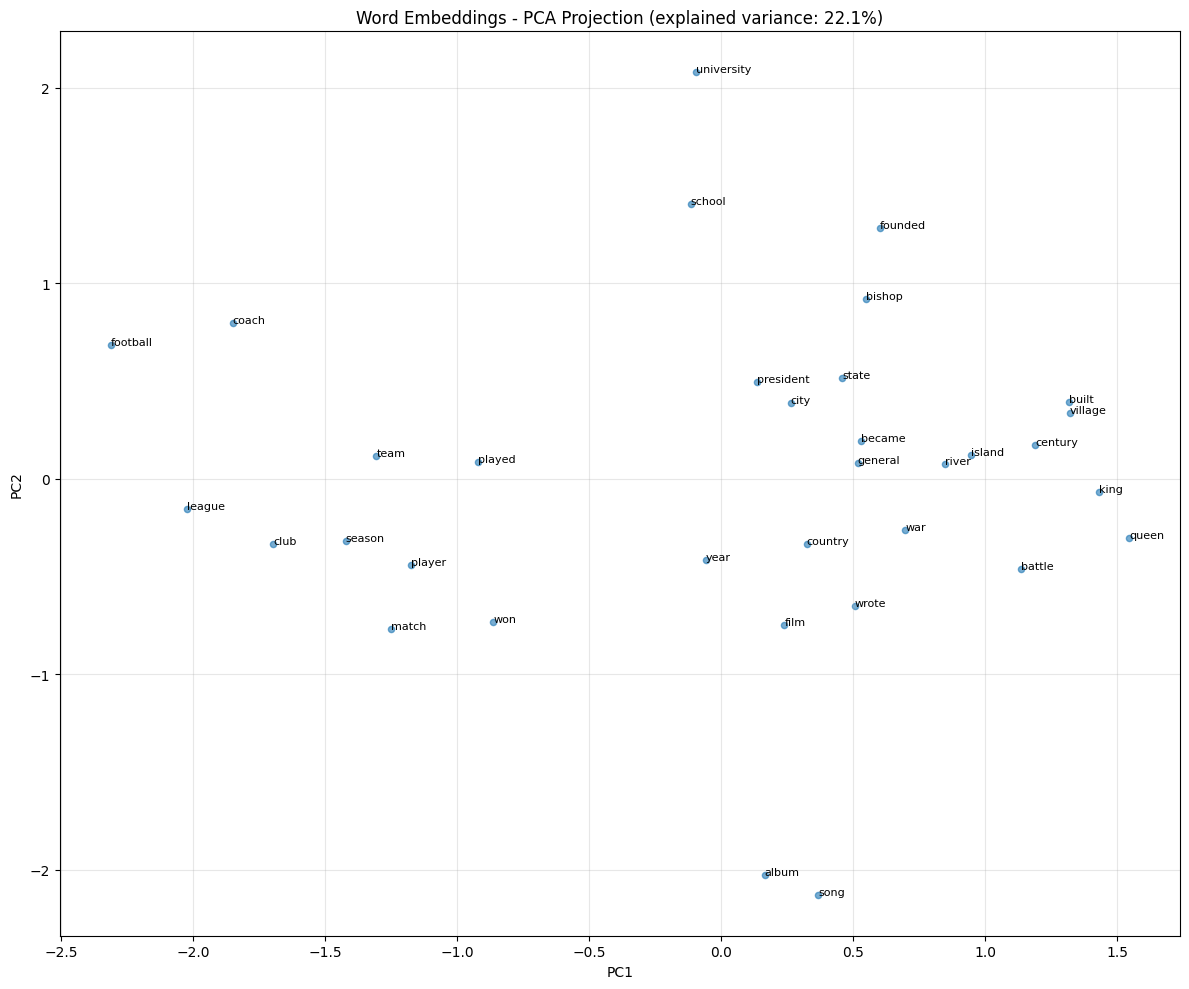

In [9]:
display_words = [
    "football", "season", "league", "team", "club", "match", "player", "coach",
    "city", "country", "state", "village", "island", "river",
    "president", "king", "queen", "general", "bishop",
    "year", "century", "war", "battle",
    "university", "school", "film", "album", "song",
    "became", "built", "founded", "won", "played", "wrote",
]

display_words = [w for w in display_words if w in word2idx]
display_indices = [word2idx[w] for w in display_words]
display_emb = embeddings[display_indices]

pca = PCA(n_components=2)
coords = pca.fit_transform(display_emb)

explained = pca.explained_variance_ratio_
total_explained = explained.sum()
print(f"Total explained variance: {100 * total_explained:.3f}%")

fig, ax = plt.subplots(figsize=(12, 10))
ax.scatter(coords[:, 0], coords[:, 1], s=20, alpha=0.6)

for i, word in enumerate(display_words):
    ax.annotate(word, (coords[i, 0], coords[i, 1]), fontsize=8)

ax.set_title(f"Word Embeddings - PCA Projection (explained variance: {total_explained:.1%})")
ax.set_xlabel(f"PC1")
ax.set_ylabel(f"PC2")
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig("../artifacts/pca_projection.png", dpi=150, bbox_inches="tight")
plt.show()

PCA is used here only as a light qualitative check. In this 2D projection, many
relatively similar words appear close to each other, which suggests that the
embeddings contain some semantic information. At the same time, the first two
principal components explain only about 22% of the variance in the selected word
vectors, so this plot shows only a limited view of the full embedding space.

## Nearest neighbors and analogies
Qualitative sanity checks:
- **Nearest neighbors**: do similar words cluster together?
- **Analogies**: does vector arithmetic (e.g. king - man + woman ≈ queen) produce reasonable results?



In [6]:
def most_similar(word, emb, word2idx, idx2word, top_k=10):
    if word not in word2idx:
        return []

    query = emb[word2idx[word]]
    emb_norms = np.linalg.norm(emb, axis=1)
    query_norm = np.linalg.norm(query)

    if query_norm == 0:
        return []

    scores = emb @ query / (emb_norms * query_norm + 1e-12)
    scores[word2idx[word]] = -np.inf

    top_ids = np.argsort(scores)[-top_k:][::-1]
    return [(idx2word[i], float(scores[i])) for i in top_ids]


idx2word = {i: w for w, i in word2idx.items()}

similarity_examples = [
    "king",
    "queen",
    "man",
    "woman",
    "france",
    "paris",
    "london",
    "england",
]

for word in similarity_examples:
    if word not in word2idx:
        print(f"'{word}' not in vocabulary")
        continue

    neighbors = most_similar(word, embeddings, word2idx, idx2word, top_k=5)
    print(f"\nMost similar to '{word}':")
    for neighbor, score in neighbors:
        print(f"  {neighbor:<15} {score:.4f}")


Most similar to 'king':
  murchad         0.7358
  ragnaill        0.7274
  veera           0.7230
  donnchad        0.7214
  ballala         0.7206

Most similar to 'queen':
  villiers        0.6740
  viii            0.6549
  elizabeth       0.6516
  duchess         0.6444
  anne            0.6407

Most similar to 'man':
  robot           0.6885
  mega            0.6618
  victim          0.6451
  wily            0.6404
  pirate          0.6244

Most similar to 'woman':
  unmarried       0.7089
  rape            0.7049
  solitude        0.6847
  marries         0.6837
  enz             0.6719

Most similar to 'france':
  italy           0.7381
  netherlands     0.7129
  naples          0.7098
  sweden          0.7052
  austria         0.7019

Most similar to 'paris':
  berlin          0.7261
  les             0.7236
  huguenots       0.7135
  diable          0.7097
  wagner          0.6978

Most similar to 'london':
  piccadilly      0.6325
  exhibition      0.6071
  stockholm       0

For domain-specific nouns, the embeddings capture clear semantic structure: `france` retrieves other European countries (Italy, Netherlands, Sweden, Austria), `england` retrieves Scotland and Wales, and `queen` retrieves royalty-related terms (elizabeth, duchess, anne). The `king` neighbors (murchad, ragnaill, donnchad) are obscure medieval rulers from Wikipedia — rare words that appear almost exclusively near "king," so their embeddings collapse onto it.

Common polysemous words like `man` and `woman` produce noisy neighbors. These words appear in too many diverse contexts for a single vector to represent well.

In [8]:
def analogy(a, b, c, emb, word2idx, idx2word, top_k=10):
    """
    Solve: a : b :: c : ?
    Vector arithmetic: b - a + c
    """
    missing = [w for w in (a, b, c) if w not in word2idx]
    if missing:
        return None, missing

    vec = emb[word2idx[b]] - emb[word2idx[a]] + emb[word2idx[c]]

    emb_norms = np.linalg.norm(emb, axis=1)
    vec_norm = np.linalg.norm(vec)

    if vec_norm == 0:
        return [], []

    scores = emb @ vec / (emb_norms * vec_norm + 1e-12)

    for w in (a, b, c):
        scores[word2idx[w]] = -np.inf

    top_ids = np.argsort(scores)[-top_k:][::-1]
    results = [(idx2word[i], float(scores[i])) for i in top_ids]
    return results, []


analogy_examples = [
    ("man", "king", "woman"),
    ("paris", "france", "london"),
]

for a, b, c in analogy_examples:
    results, missing = analogy(a, b, c, embeddings, word2idx, idx2word, top_k=5)

    if missing:
        print(f"\n{a}:{b}::{c}:? skipped; missing words: {missing}")
        continue

    print(f"\n{a}:{b}::{c}:?")
    for word, score in results:
        print(f"  {word:<15} {score:.4f}")


man:king::woman:?
  martyr          0.6351
  assyrian        0.6219
  eldest          0.6203
  sidonian        0.6195
  regency         0.6159

paris:france::london:?
  sweden          0.5855
  denmark         0.5754
  netherlands     0.5635
  fiji            0.5556
  scotland        0.5547


Analogy retrieval does not produce the intended answers. `paris:france::london:?` returns countries (Sweden, Denmark, Netherlands) rather than "england" — the model captures a capital-to-country direction but it is too noisy for exact retrieval. `man:king::woman:?` returns unrelated terms, reflecting the poor embeddings for polysemous words like `man` and `woman` discussed above.

This is expected: analogy evaluation is demanding, and the original word2vec results relied on corpora roughly 1000× larger than WikiText-2.

## Conclusion

The trained skip-gram embeddings show clear improvement over random initialization:
ρ = 0.4396 vs 0.0361 on WordSim-353, nearest neighbors that reflect genuine semantic
groupings, and partial structure in analogy directions even
though exact retrieval fails.